# Bayesian credit limits for a newly launched SME business card

**All data in this notebook is simulated.** No real customers, lenders or products are involved.

A lender has just launched a business credit card. After 12 months some customer segments have only a
few dozen accounts, so estimating default and activation rates separately per segment gives noisy,
unreliable numbers. This notebook walks through a hierarchical Bayesian model that shares information
across segments, updates as monthly data arrives, and turns its estimates into suggested credit limits.

Each section runs one stage of the project (the code lives in `src/`). Running the whole notebook takes
about 7 minutes. `python run_all.py` does the same without the commentary.

In [1]:
import logging
import sys
import warnings
from pathlib import Path

import pandas as pd
import pymc  # noqa: F401  (imported first so its log level can be set below)
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
logging.getLogger("pymc").setLevel(logging.ERROR)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def figure(name, width=950):
    display(Image(filename=str(ROOT / "figures" / name), width=width))


def report(name):
    return pd.read_csv(ROOT / "reports" / name)

## Stage 1: simulated data with known true parameters

We simulate the portfolio so we know the right answer and can check whether the models find it.

* **12 segments**: 4 industries x 3 business-size bands, deliberately unbalanced (22 to 600 accounts).
* **Monthly cohorts** over 12 months, growing as the product ramps up, so later cohorts have less history.
* Each account may **activate** within 60 days; only activated accounts carry a balance, so only they can
  **default**. The default rate is therefore P(default within 12 months | activated).
* **Censoring**: at the end of month 12 most accounts have not yet had a full year, so many future
  defaults are not visible yet. The true outcomes are kept in a separate file the models never see.

In [2]:
import data_generation

data_generation.main()
accounts = pd.read_csv(ROOT / "data" / "accounts.csv")
truth_accounts = pd.read_csv(ROOT / "data" / "accounts_truth.csv")
accounts.head()

Accounts: 2,870
                           segment  n_accounts  true_default_rate  true_activation_rate
0             Construction | Micro         600              0.105                 0.570
1             Construction | Small         260              0.087                 0.725
2            Construction | Medium          70              0.059                 0.751
3                   Retail | Micro         520              0.064                 0.661
4                   Retail | Small         210              0.045                 0.655
5                  Retail | Medium          28              0.040                 0.756
6    Professional Services | Micro         450              0.049                 0.658
7    Professional Services | Small         300              0.035                 0.737
8   Professional Services | Medium          90              0.030                 0.837
9              Hospitality | Micro         240              0.127                 0.506
10             H

,account_id,industry,size_band,segment,cohort_month,months_on_book,credit_limit,activated_60d,avg_monthly_spend,utilisation,defaulted,default_month,exposure_fraction
0,A00001,Construction,Medium,Construction | Medium,1,12,15000.0,1.0,14234.89,0.3731,0,NaN,1.0
1,A00002,Construction,Medium,Construction | Medium,1,12,15000.0,1.0,7246.83,0.4711,0,NaN,1.0
2,A00003,Construction,Medium,Construction | Medium,1,12,15000.0,1.0,15914.93,0.2416,0,NaN,1.0
3,A00004,Construction,Medium,Construction | Medium,1,12,15000.0,1.0,5396.20,0.6272,1,2.0,1.0
4,A00005,Construction,Medium,Construction | Medium,1,12,15000.0,1.0,18800.62,0.4410,0,NaN,1.0


Censoring matters: only part of the true 12-month defaults are visible at the snapshot, so a naive
"defaults / activated accounts" rate badly understates risk.

In [3]:
print(f"Visible defaults at month 12: {accounts['defaulted'].sum()}")
print(f"True 12-month defaults (hidden from the models): {truth_accounts['default_12m_true'].sum()}")

Visible defaults at month 12: 55
True 12-month defaults (hidden from the models): 124


## Stage 2: priors and prior predictive checks

Each segment's rate is built on the log-odds scale from a portfolio average plus industry, size-band and
segment effects. Each effect has its own learned spread, so the data decide how much segments share.

* **Default**: average centred on 5%, so the portfolio rate is 95% likely to be between about 1.2% and 19%.
* **Activation**: centred on 60%, wider (about 17% to 91%), because less is known in advance.
* **Spreads**: industry and size HalfNormal(0.4), segment-specific HalfNormal(0.25).

A *prior predictive check* simulates data from the priors alone. The left panel below shows why "vague"
priors are a trap: Normal(0, 10) on the log-odds scale piles up at 0% and 100%.

Share of implied segment default rates within 0-20%:
  Vague: Normal(0, 10) on log-odds         44.5%
  Generic: Normal(0, 1.5) on log-odds      17.5%
  Chosen: hierarchical, centred on 5%      94.5%



Chosen priors:
  default_rate_quantiles           [0.008 0.027 0.05  0.089 0.257]
  share_default_rate_le_20pct      0.951
  share_default_rate_gt_50pct      0.002
  activation_rate_quantiles        [0.125 0.598 0.94 ]
  spread_ratio_quantiles           [ 1.517  3.503 17.164]
  pp_defaults_quantiles            [  9.  47. 194.]
  pp_activation_share_quantiles    [0.165 0.594 0.918]
  observed_defaults                52
  observed_activation_share        0.661


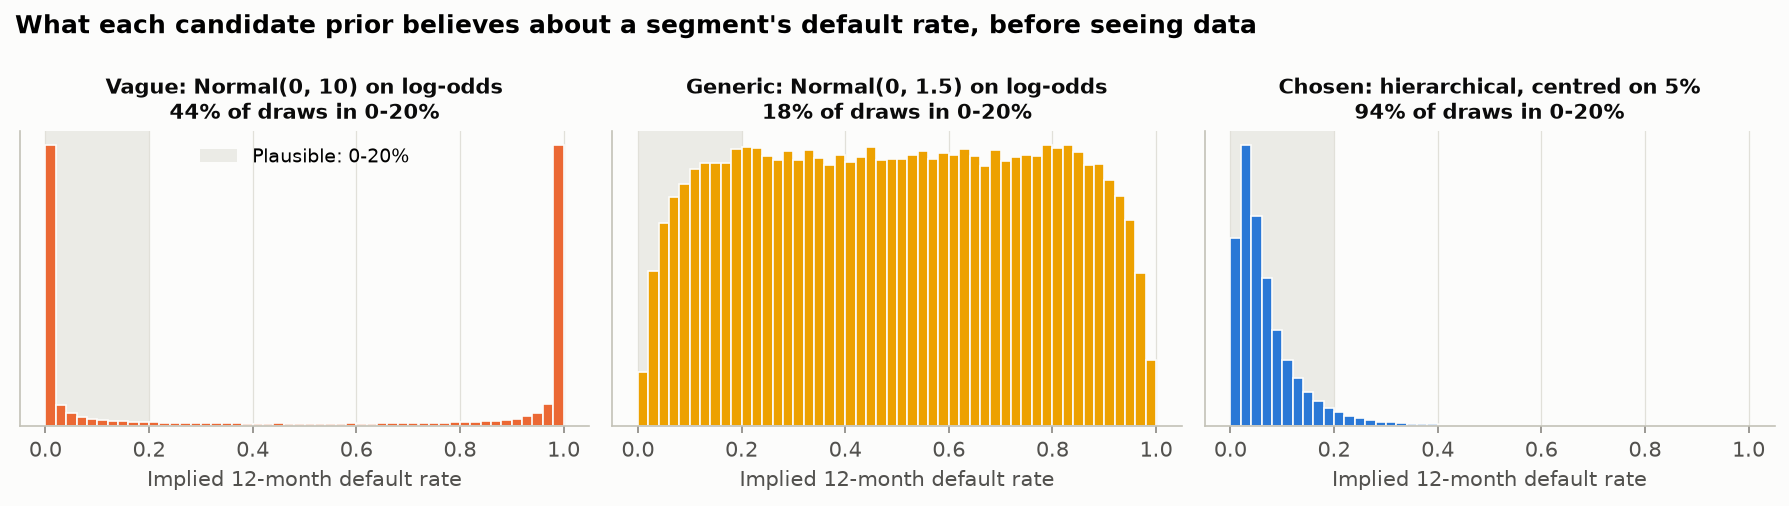

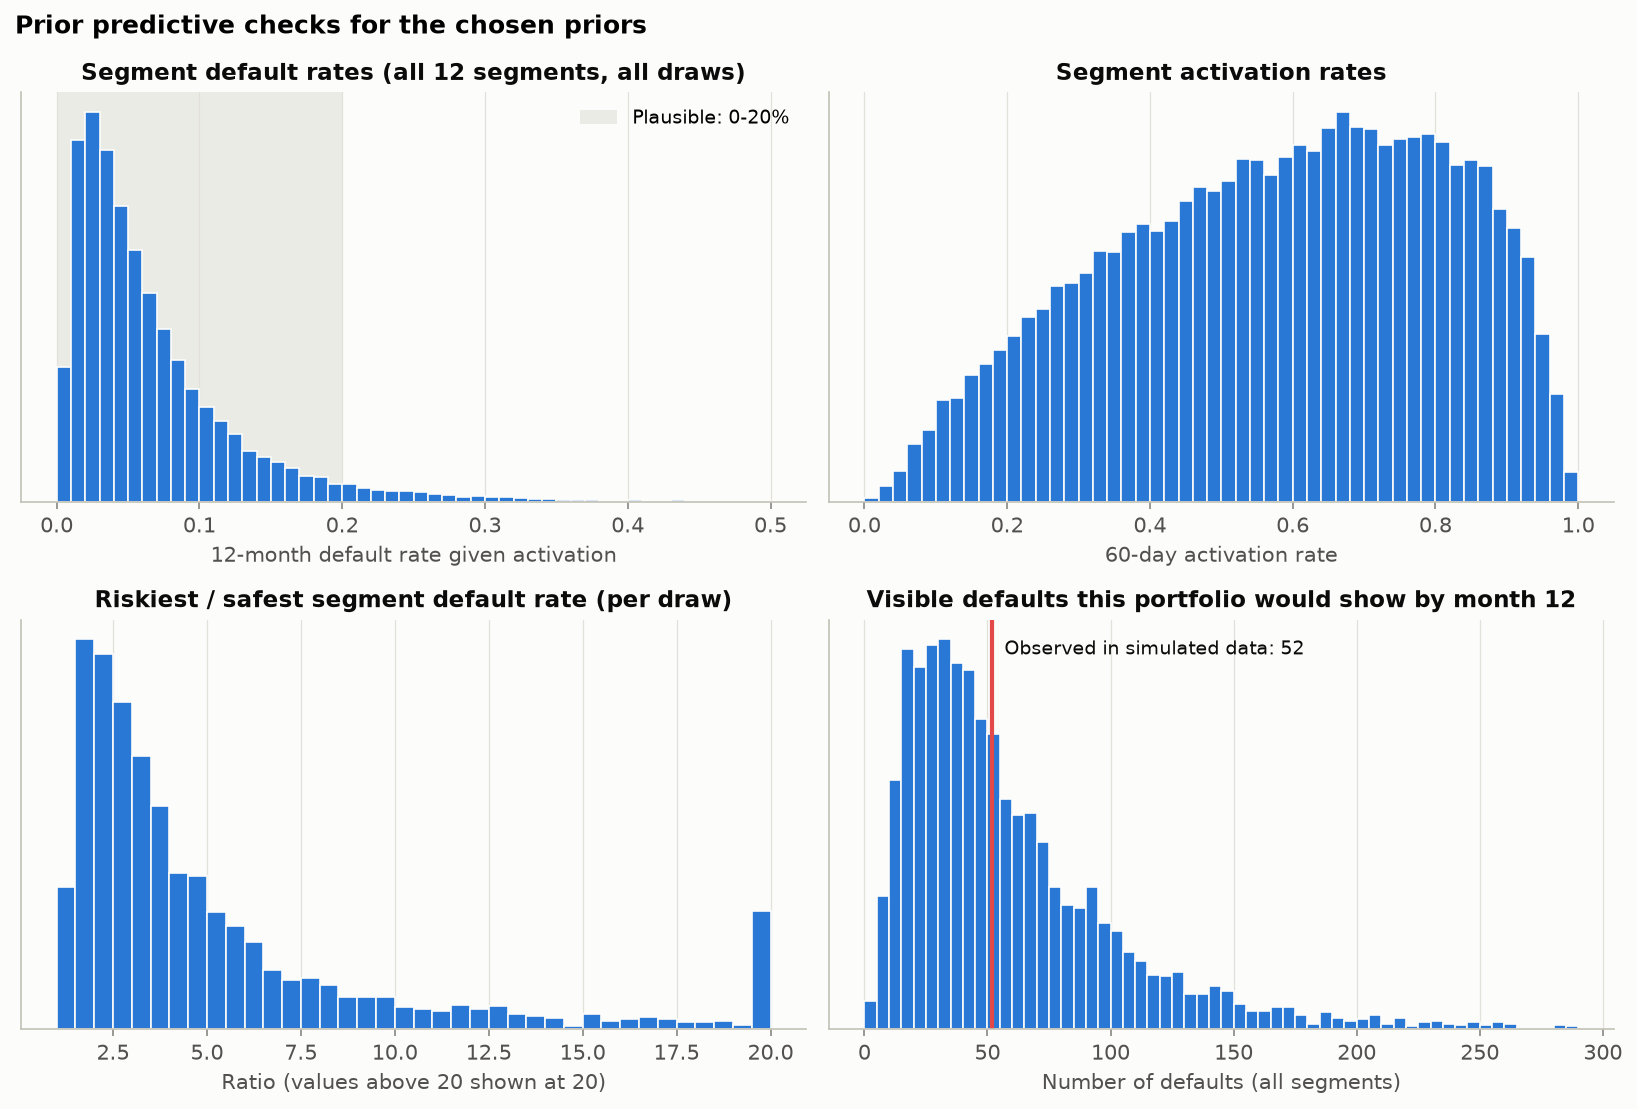

In [4]:
import prior_checks

prior_checks.main()
figure("prior_candidates.png")
figure("prior_predictive_checks.png", width=800)

## Stage 3: the hierarchical model and two baselines

* **Hierarchical (partial pooling)**: the crossed industry + size + segment model above.
* **Complete pooling**: one rate for every segment.
* **No pooling**: an independent rate per segment, sharing nothing.

Censoring is handled with an exposure adjustment: an activated account observed for *m* months shows a
default with probability `rate x m/12` (assuming defaults are spread evenly over the year).

Convergence checks:

* **R-hat** compares the spread within each of the 4 chains to the spread between them; ~1.00 means the
  chains agree.
* **Effective sample size (ESS)** is how many independent draws the correlated draws are worth.
* **Divergences** flag regions the sampler could not explore safely; there should be none.

   model  n_parameters  max_r_hat  min_ess_bulk  min_ess_tail  divergences
complete            26      1.001      2513.737      2378.182            0
    none            48      1.005      5986.367      2286.760            0
 partial            70      1.003      1636.133      1267.641            0


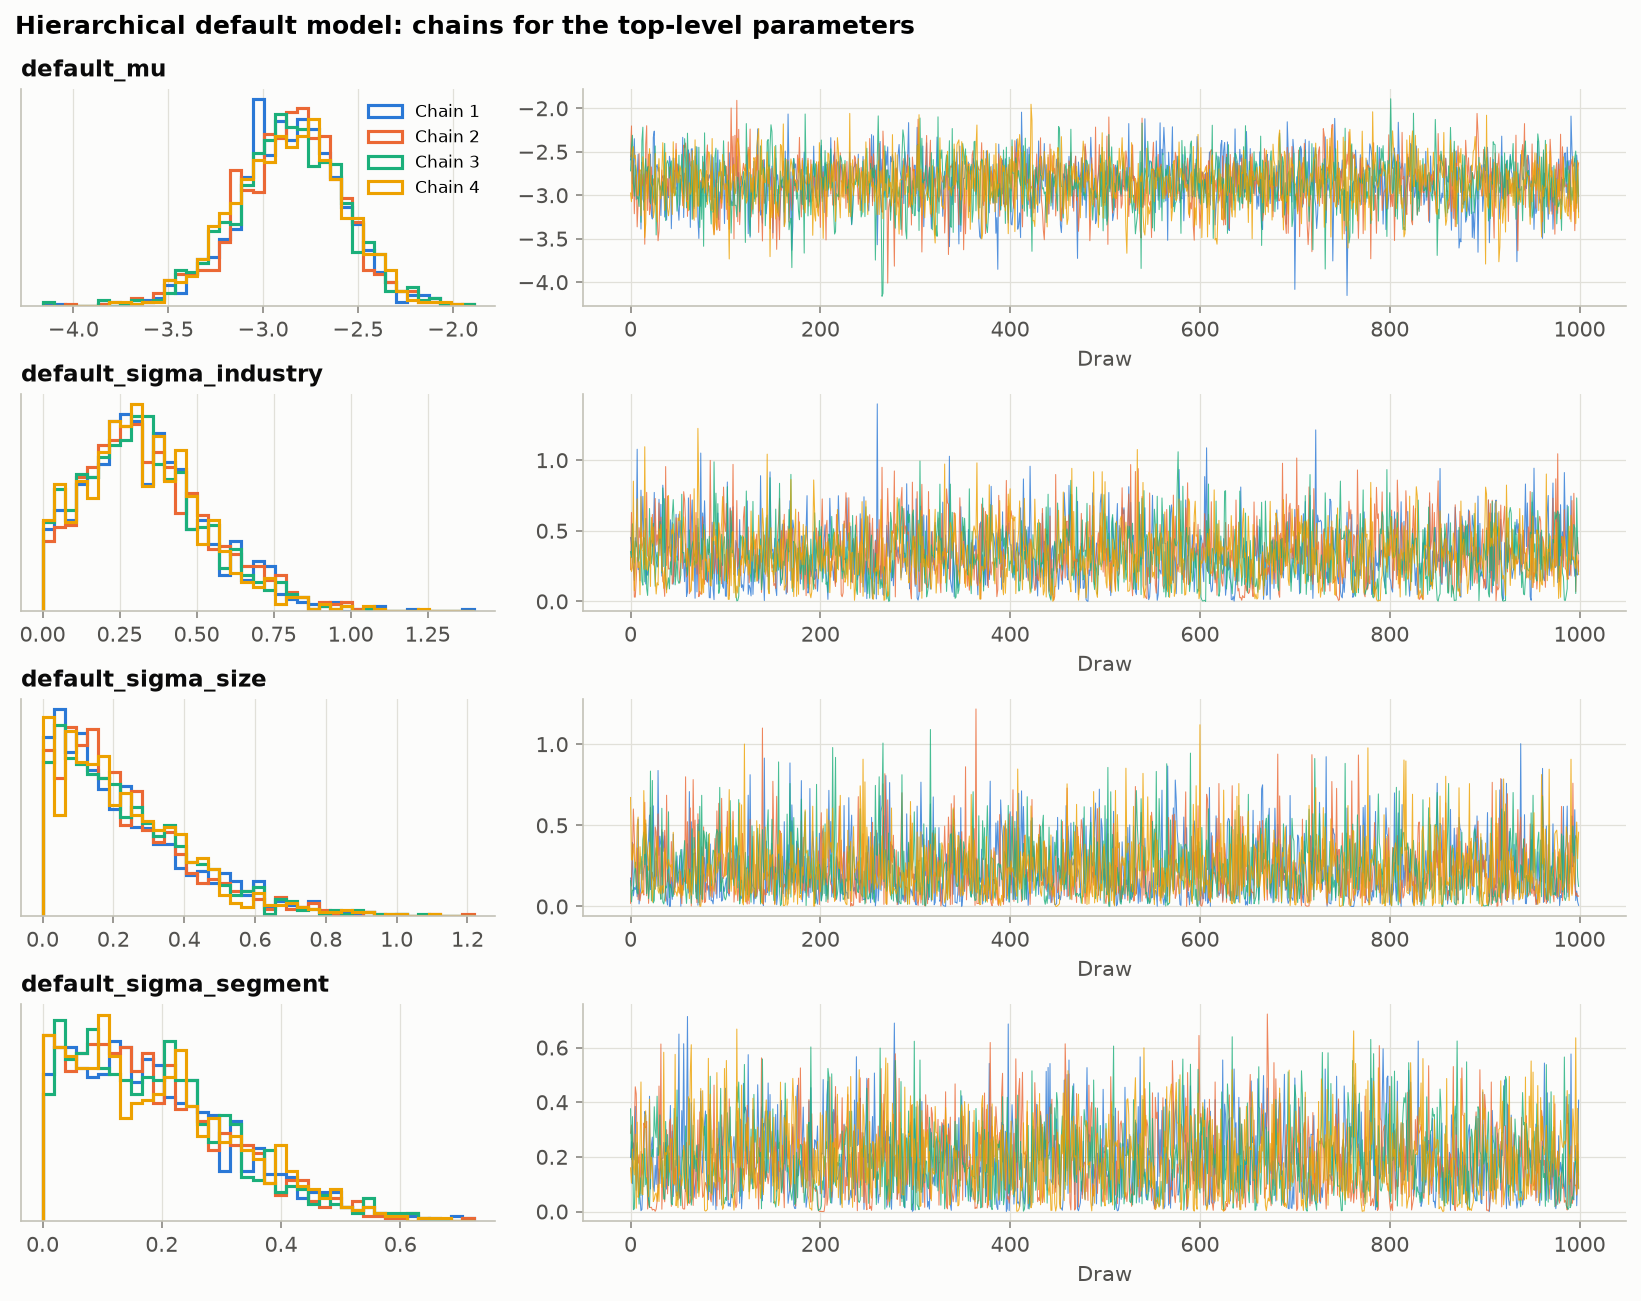

In [5]:
import fit_models

fit_models.main()
figure("convergence_trace.png", width=850)

## Stage 4: validation

1. **Parameter recovery**: estimates against the true segment rates.
2. **Posterior predictive checks**: can each fitted model reproduce the data it saw?
3. **Calibration** on a fresh, held-out portfolio.
4. **Prior sensitivity**: refit with different default priors.

In [6]:
import validate

validate.main()

Parameter recovery (90% intervals):
   outcome    model size_group  segments  mean_abs_error  coverage  mean_interval_width
activation complete      large         7          0.0565    0.4286               0.0307
activation complete      small         5          0.0922    0.0000               0.0307
activation     none      large         7          0.0380    0.7143               0.0885
activation     none      small         5          0.0500    0.8000               0.2045
activation  partial      large         7          0.0351    0.7143               0.0786
activation  partial      small         5          0.0451    0.6000               0.1313
   default complete      large         7          0.0276    0.2857               0.0276
   default complete      small         5          0.0183    0.4000               0.0276
   default     none      large         7          0.0201    1.0000               0.0764
   default     none      small         5          0.0164    1.0000               0.1


Posterior predictive checks:
   model                               statistic  observed  replicated_median  p_value
complete                  Total visible defaults   52.0000            51.0000   0.4942
complete    Spread of segment default rates (SD)    0.0179             0.0194   0.6388
complete Spread of segment activation rates (SD)    0.1147             0.0478   0.0012
    none                  Total visible defaults   52.0000            52.0000   0.5250
    none    Spread of segment default rates (SD)    0.0179             0.0269   0.9282
    none Spread of segment activation rates (SD)    0.1147             0.1274   0.7928
 partial                  Total visible defaults   52.0000            51.0000   0.4895
 partial    Spread of segment default rates (SD)    0.0179             0.0218   0.7855
 partial Spread of segment activation rates (SD)    0.1147             0.1187   0.5965



Hold-out calibration:
   model    outcome segments  accounts  log_loss   brier  predicted_total  observed_total
complete    default      all      5648   0.24886 0.06342        342.76592             384
complete    default    small       642   0.22475 0.05569         38.96171              38
complete activation      all      8610   0.64372 0.22570       5692.08244            5648
complete activation    small       870   0.58896 0.19929        575.15816             642
    none    default      all      5648   0.24189 0.06248        351.14129             384
    none    default    small       642   0.21857 0.05512         33.50964              38
    none activation      all      8610   0.63318 0.22068       5679.95733            5648
    none activation    small       870   0.57048 0.18982        677.05391             642
 partial    default      all      5648   0.24224 0.06261        341.79242             384
 partial    default    small       642   0.22034 0.05524         35.63350    


Prior sensitivity: largest change in a segment's posterior mean default rate (pp):
                               segment  n_accounts  abs_shift_pp
variant                                                         
Centred on 10%   Construction | Medium          70          0.32
Centred on 2%     Hospitality | Medium          22          0.40
Spreads doubled   Construction | Micro         600          0.59
Spreads halved    Construction | Micro         600          0.99


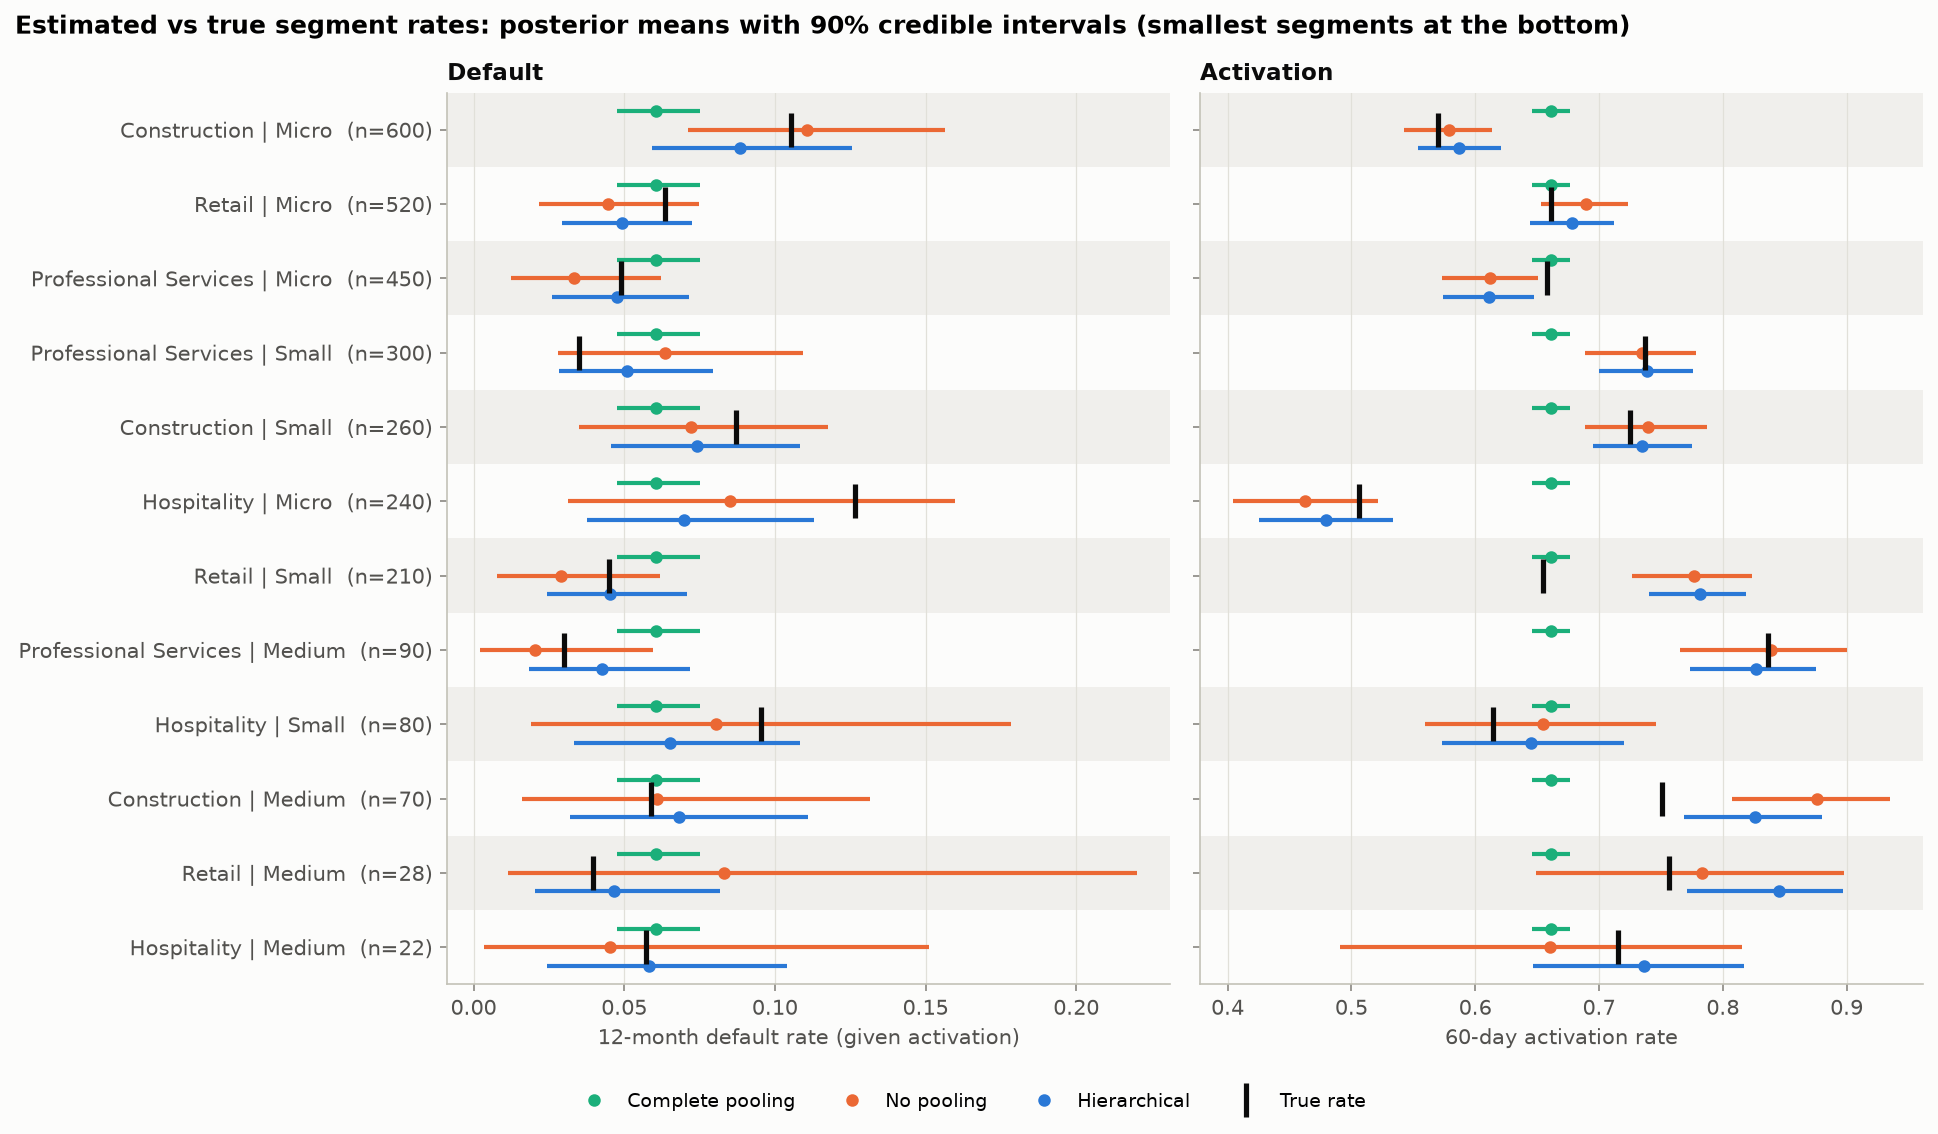

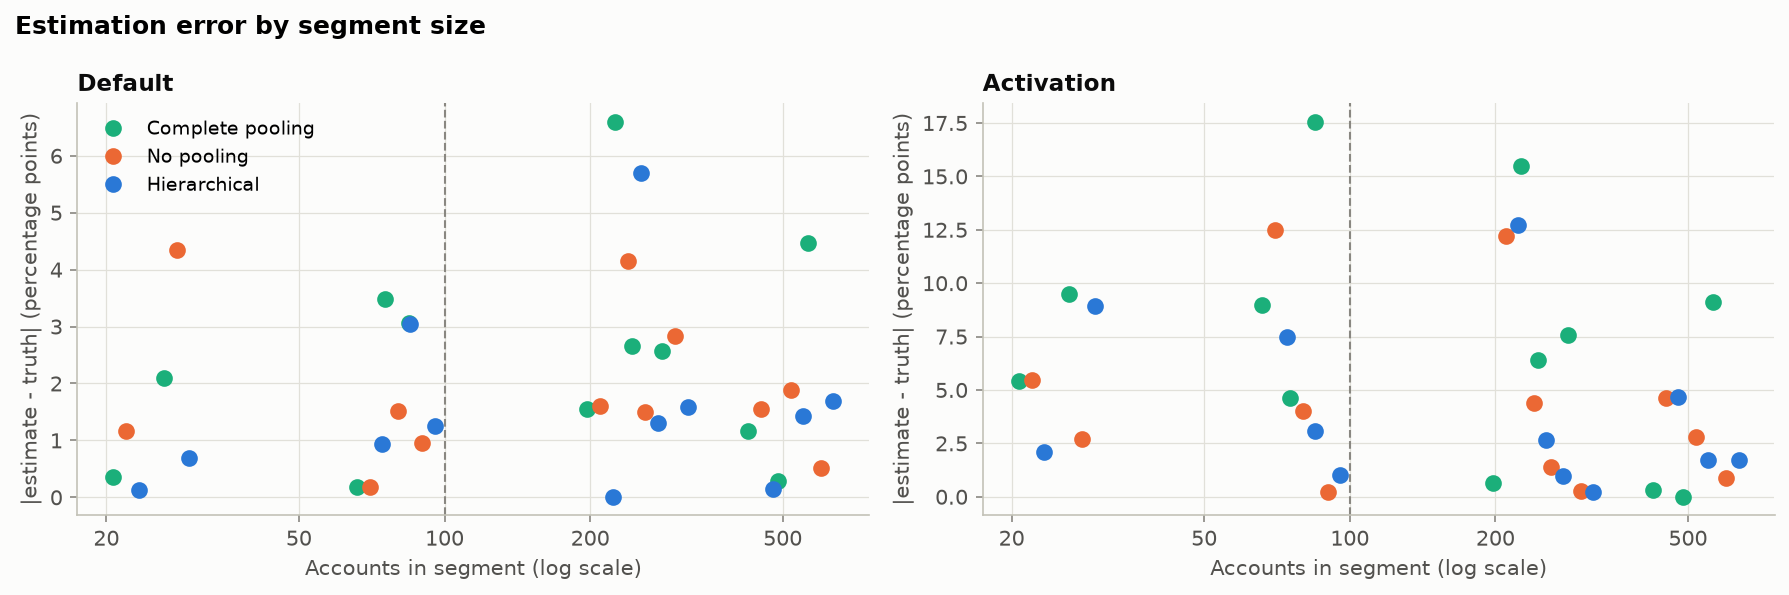

In [7]:
figure("validation_recovery.png")
figure("validation_error_by_size.png")

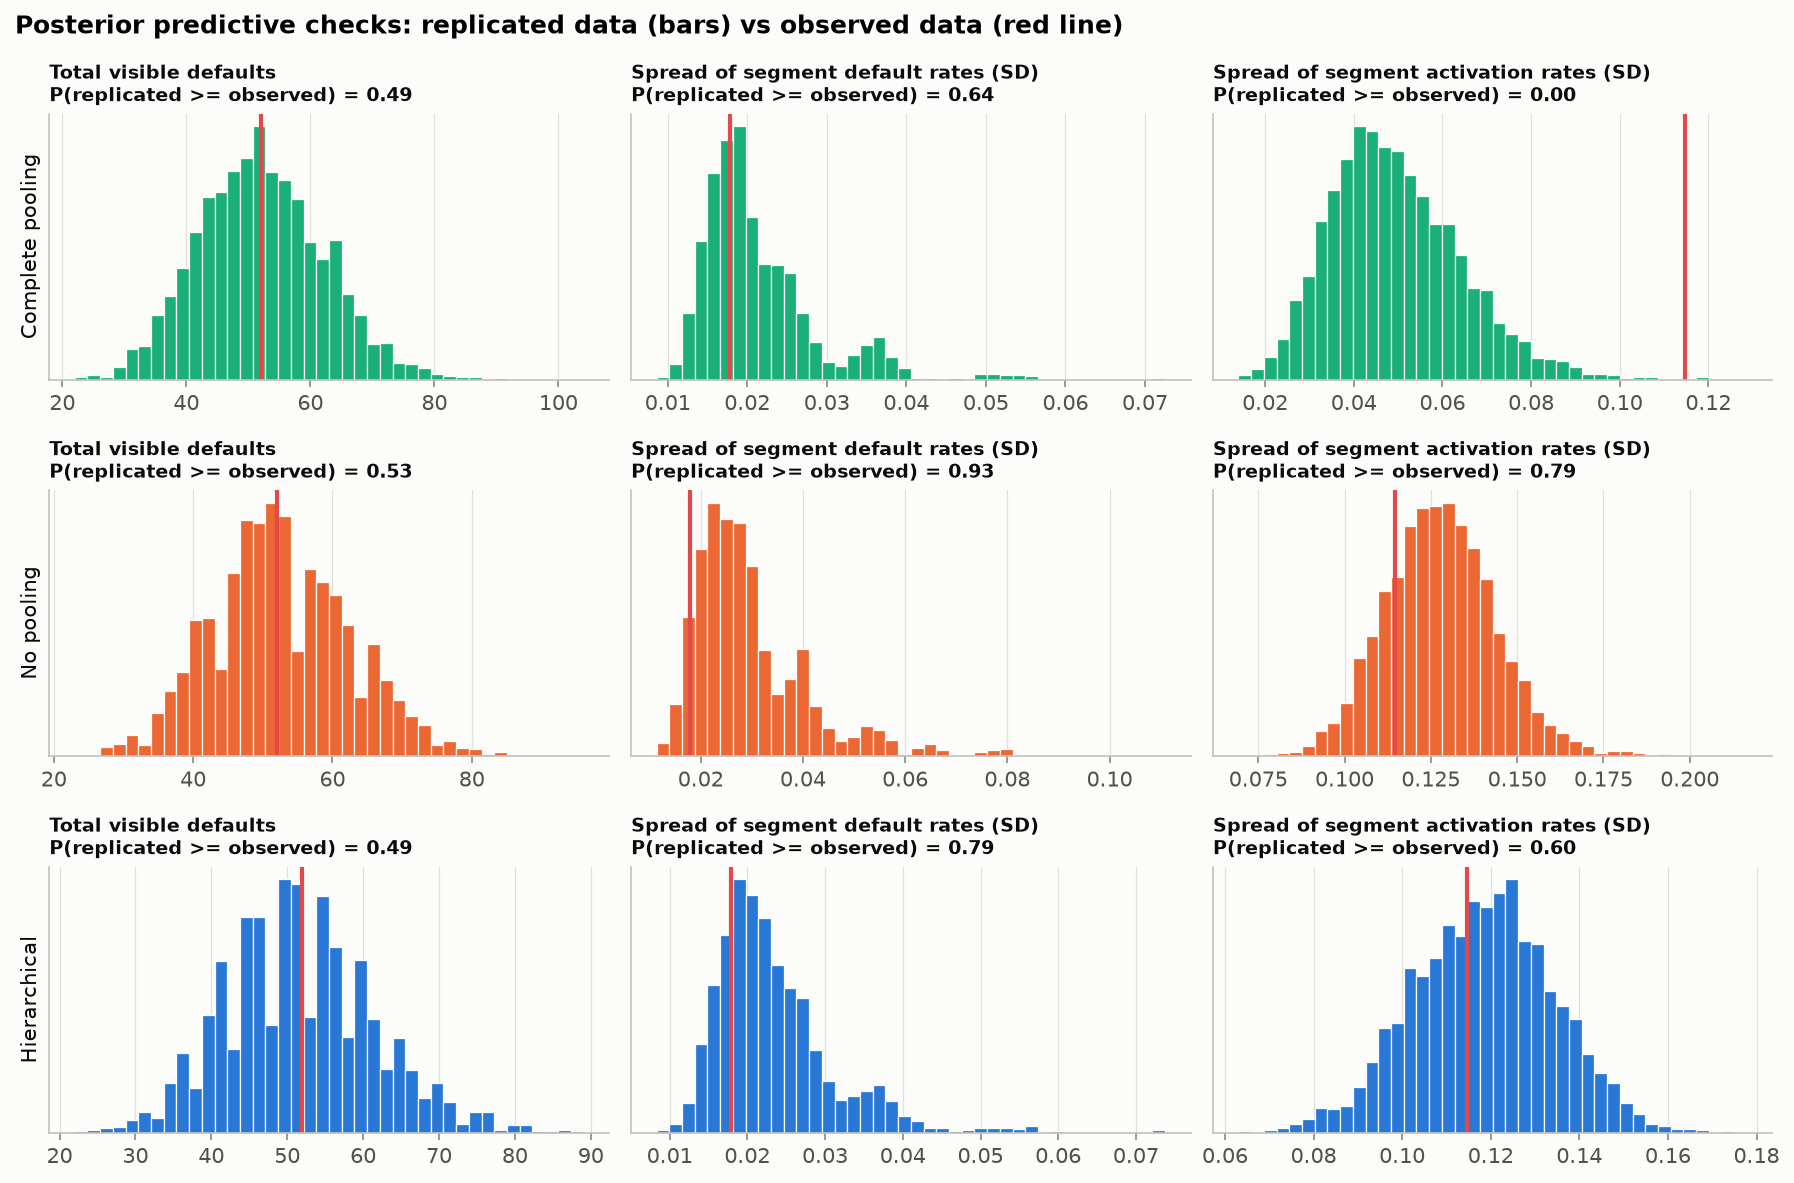

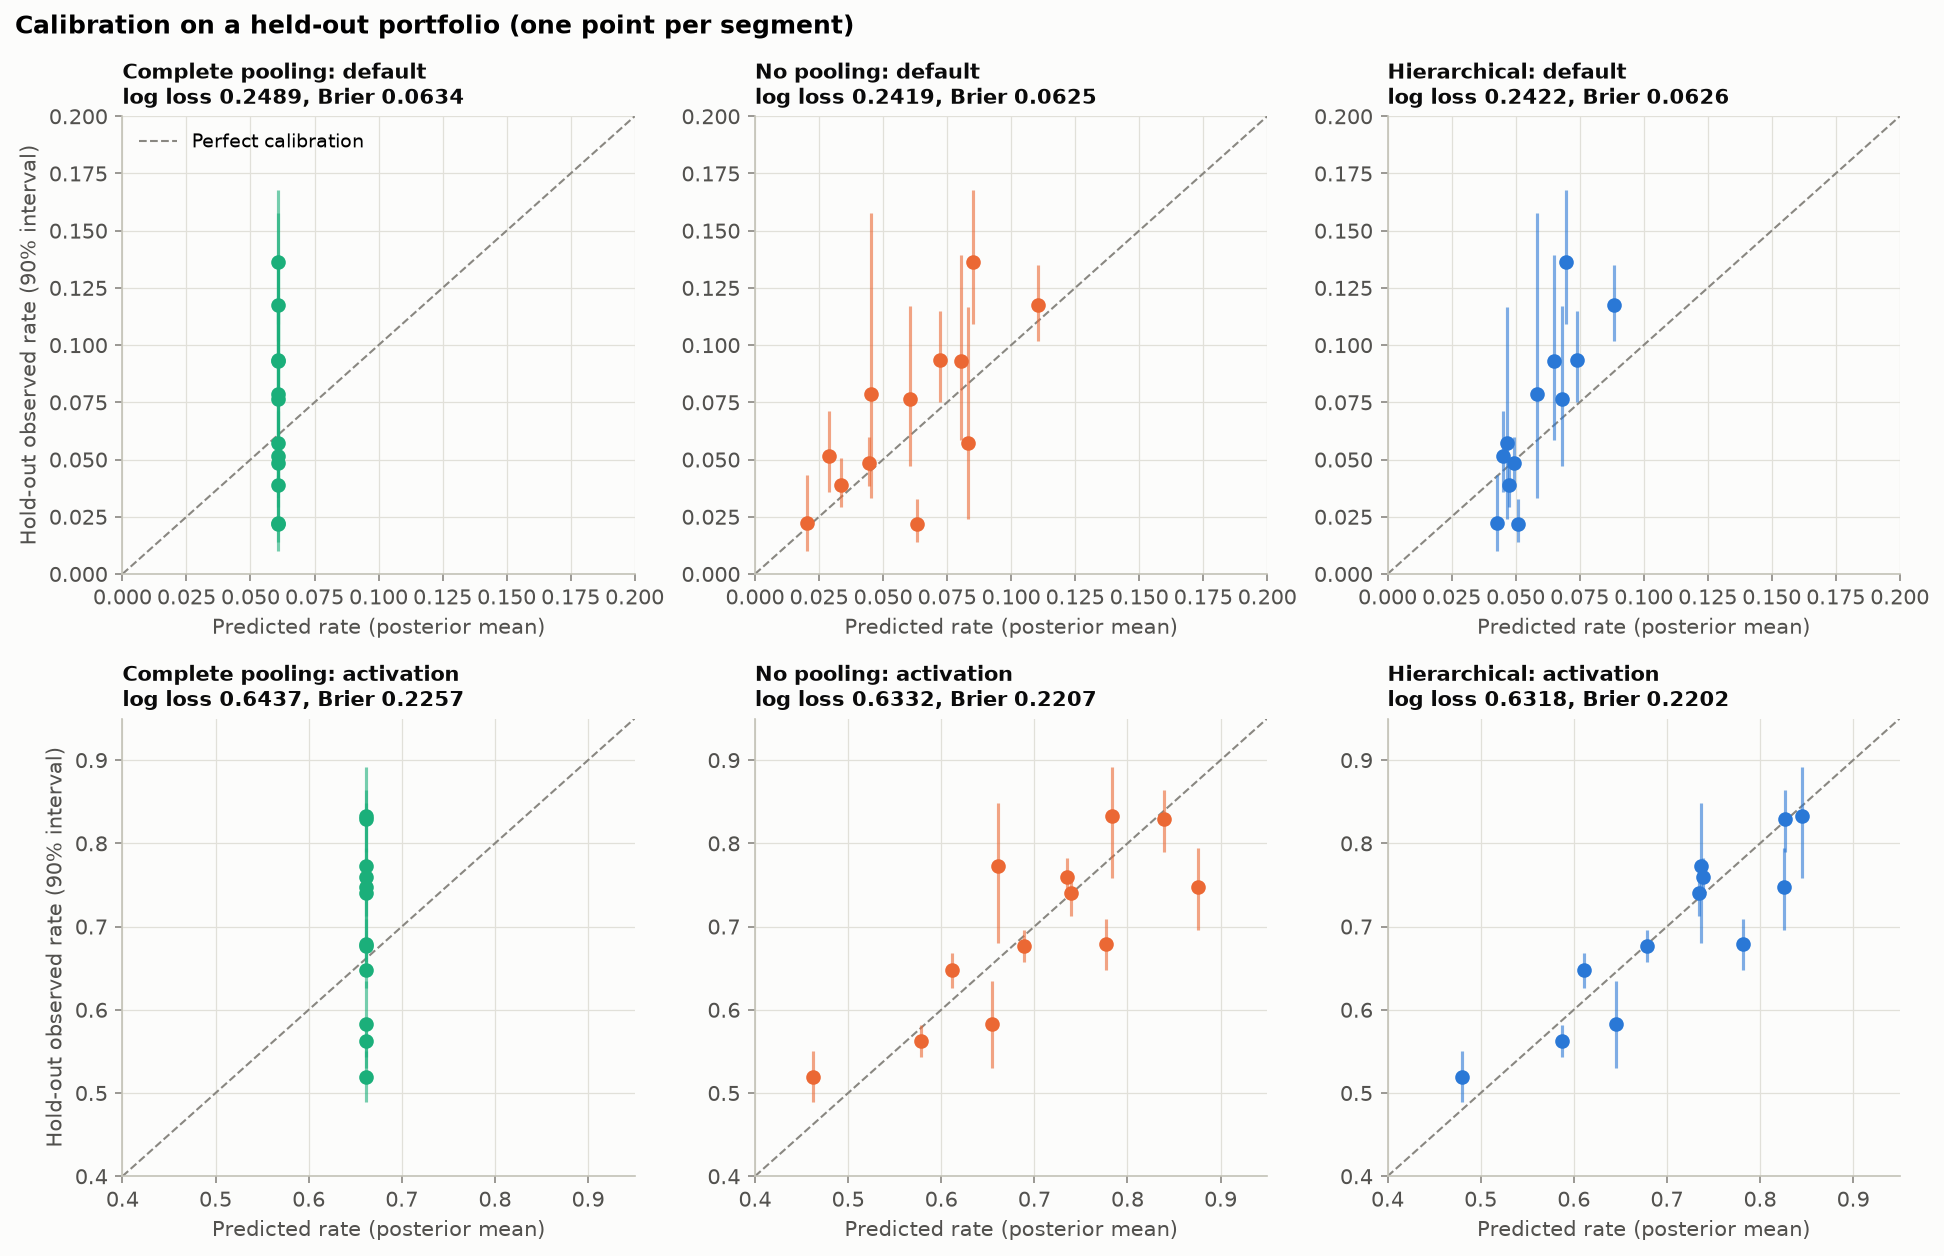

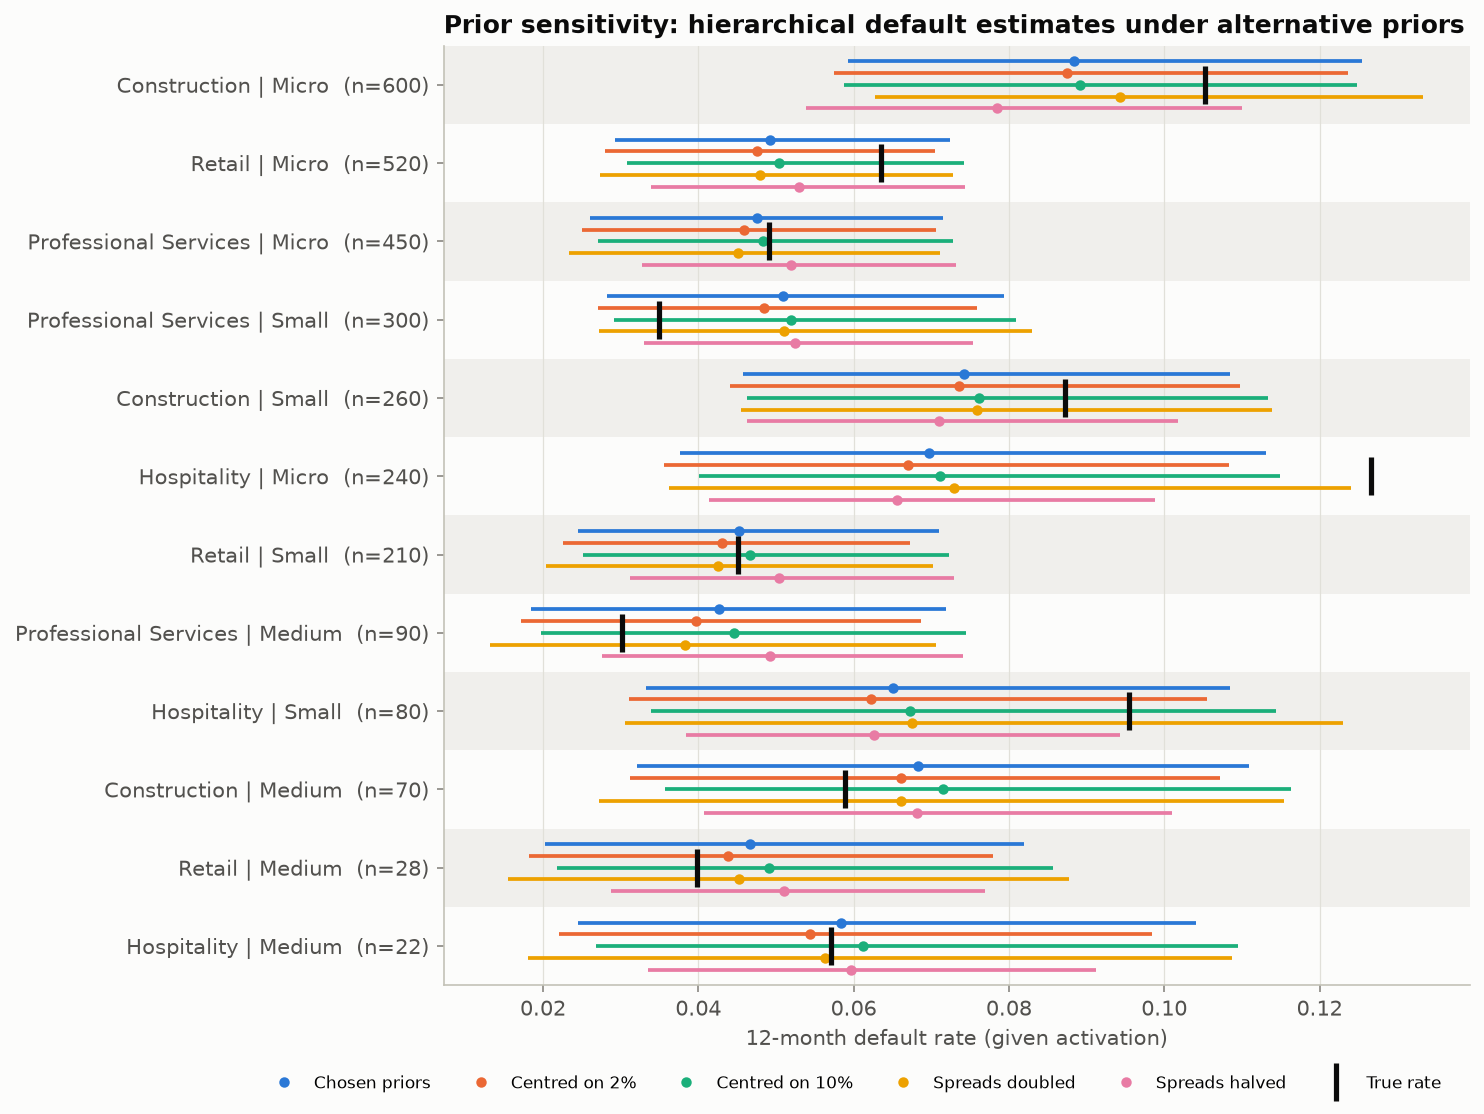

In [8]:
figure("validation_ppc_statistics.png")
figure("validation_calibration.png")
figure("validation_prior_sensitivity.png", width=800)

### Is this one dataset typical? The multi-seed simulation study

Any single simulated dataset can be lucky or unlucky. `src/simulation_study.py` repeats
simulate -> fit -> score on 20 fresh datasets with the same true rates. It takes about 25 minutes, so
here we load its saved results instead of rerunning it.

In [9]:
summary = report("simulation_study_summary.csv")
summary.assign(
    mean_abs_error_pp=summary["mean_abs_error"] * 100,
    mean_interval_width_pp=summary["mean_interval_width"] * 100,
)[["outcome", "model", "size_group", "seeds", "mean_abs_error_pp", "coverage", "mean_interval_width_pp"]].round(2)

,outcome,model,size_group,seeds,mean_abs_error_pp,coverage,mean_interval_width_pp
0,activation,complete,large,20,6.14,0.25,3.12
1,activation,complete,small,20,10.25,0.00,3.12
2,activation,none,large,20,2.05,0.91,9.06
3,activation,none,small,20,4.32,0.95,21.62
4,activation,partial,large,20,2.05,0.87,8.57
5,activation,partial,small,20,3.31,0.97,15.61
6,default,complete,large,20,2.87,0.23,2.91
7,default,complete,small,20,2.48,0.28,2.91
8,default,none,large,20,1.96,0.91,8.38
9,default,none,small,20,2.70,0.97,14.67


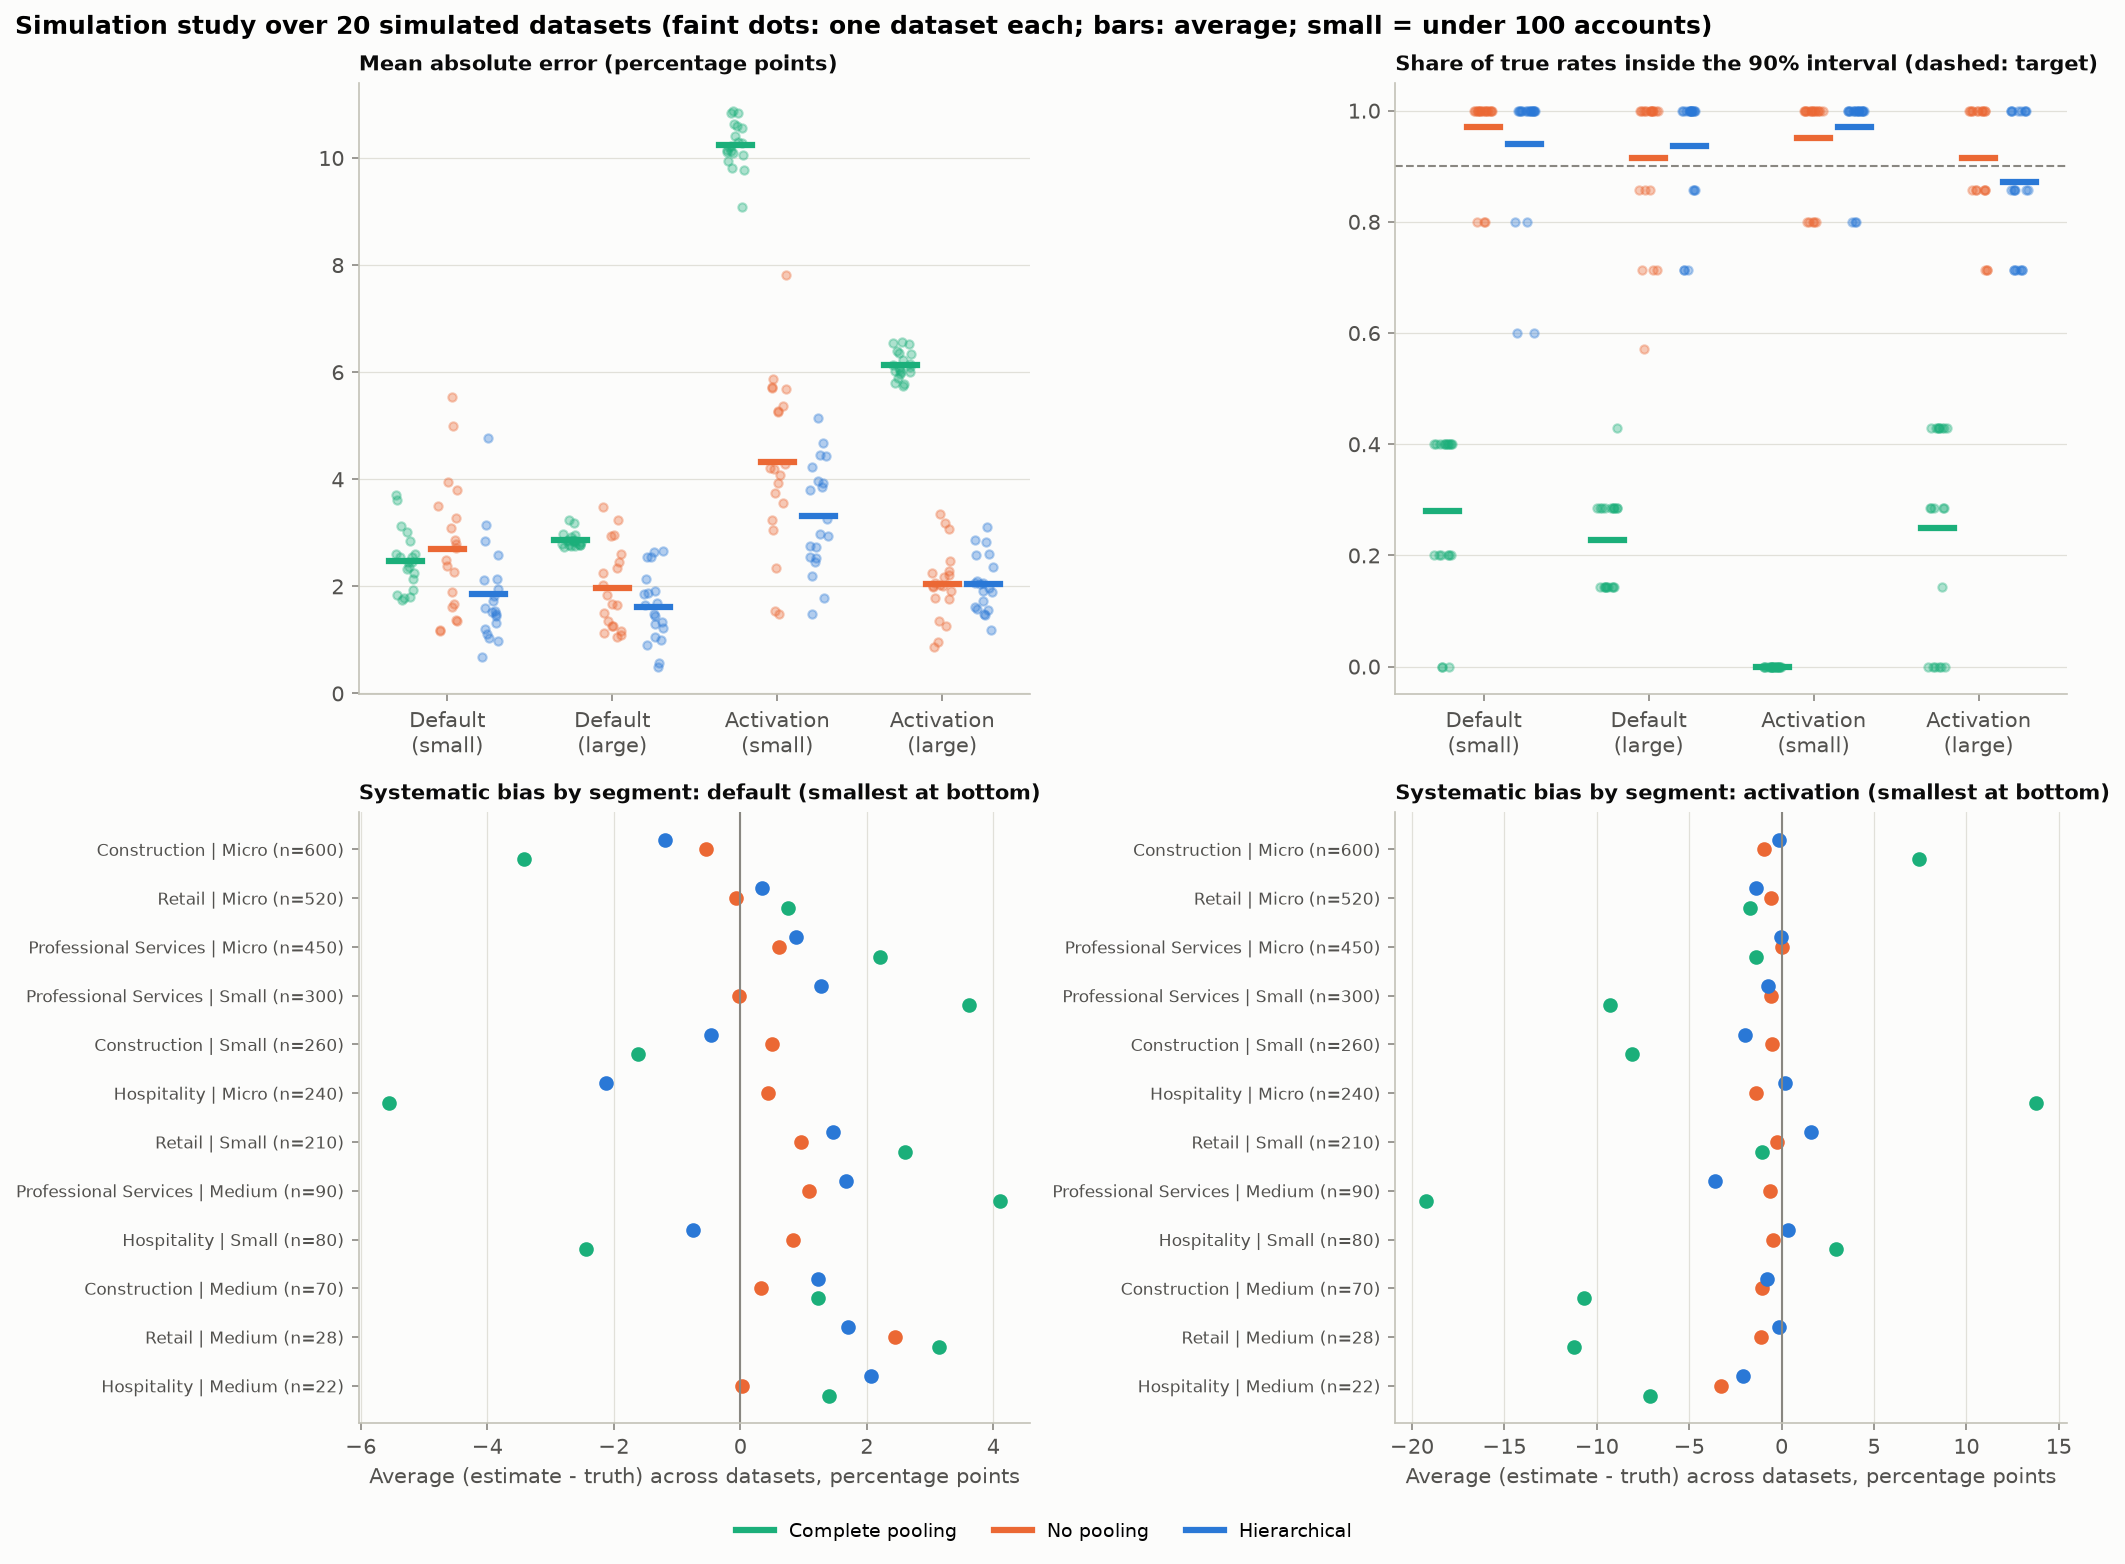

In [10]:
figure("simulation_study.png")

**What the validation shows**

* Across 20 datasets the hierarchical model has the lowest error for default in both small and large
  segments, and for activation in small segments. Its 90% intervals cover the truth about as often as
  they should (87-97%), and for small segments they are about 40% narrower than no pooling's.
* Complete pooling is clearly wrong: posterior predictive checks reject it without needing the truth.
* The cost of pooling is **systematic shrinkage bias**: the riskiest segment (Hospitality | Micro, true
  12.7%) is under-estimated by about 2 percentage points on average, and the safest segments are
  slightly over-estimated. This matters for lending, which is why the limit rule below uses an upper
  percentile of risk, not the average.

## Stage 5: updating month by month

At the end of each month we refit on everything visible at that date. (Re-using last month's posterior
as this month's prior would double-count accounts that are seen again, one month older.) At month 1 no
account has passed its 60-day activation window, so the month-1 estimate is the prior.

month 1 done


month 2 done


month 3 done


month 4 done


month 5 done


...

month 10 done


month 11 done


month 12 done


Monthly fits: max R-hat 1.005, min bulk ESS 944, min tail ESS 1196, total divergences 0



Hospitality | Medium: width of 90% default interval (pp)
month      1     2     3     4     5     6     7     8     9     10    11    12
model                                                                          
none     36.8  35.6  34.0  34.3  32.0  28.0  25.7  22.0  20.7  18.4  15.7  13.7
partial  19.5  34.0  23.2  19.3  15.1  12.7  10.2   8.3   8.0   7.8   8.7   7.9

Construction | Micro: width of 90% default interval (pp)
month      1     2     3     4     5     6     7     8     9     10   11   12
model                                                                        
none     36.6  24.9  34.1  38.1  24.1  16.8  14.2  12.9  10.7  10.4  9.4  8.2
partial  18.6  27.2  18.1  18.5  12.7   9.8   8.4   7.7   7.2   7.4  7.5  6.6


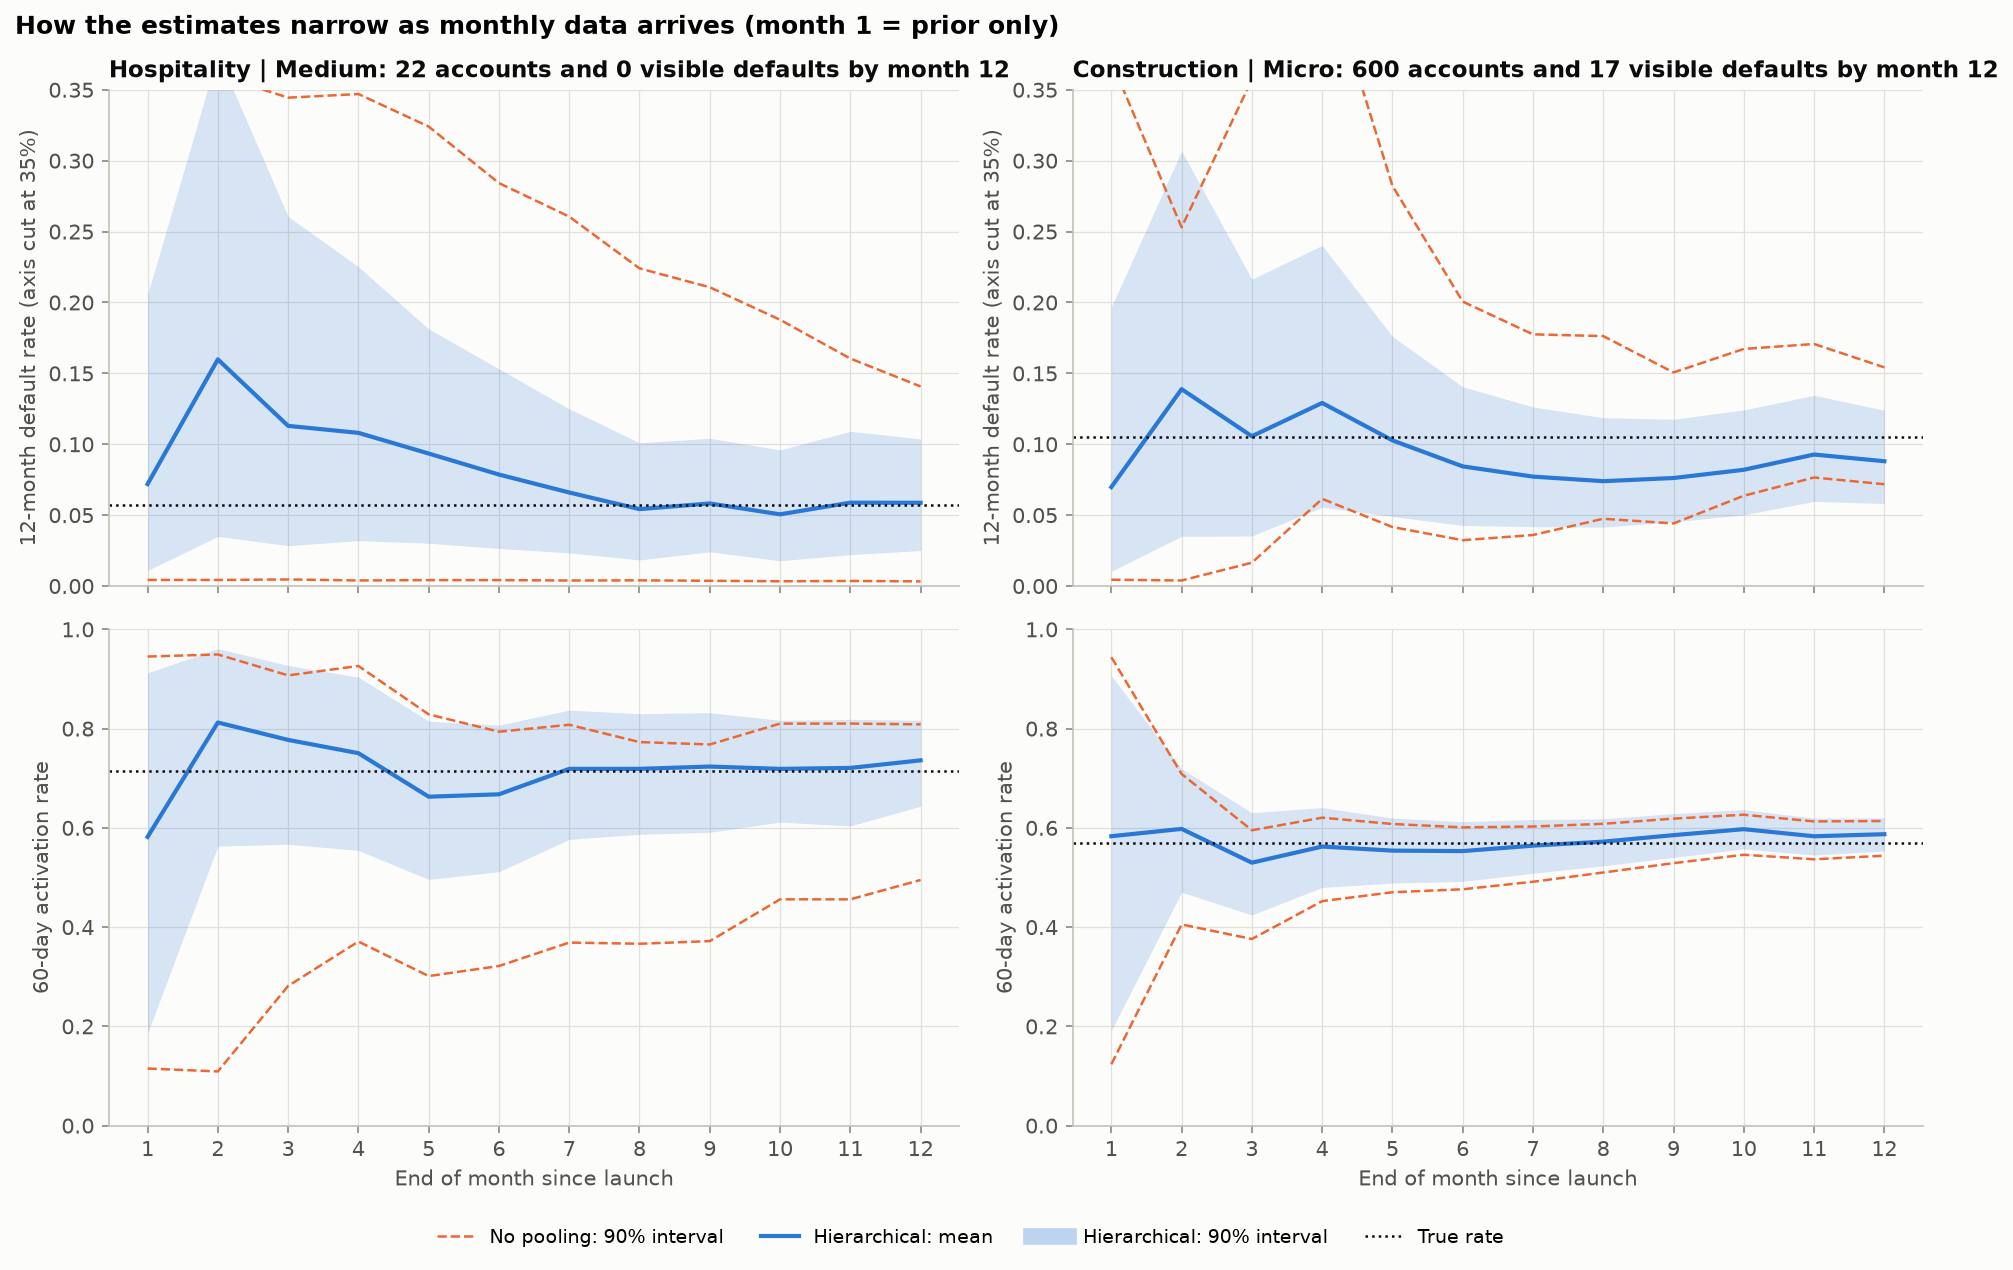

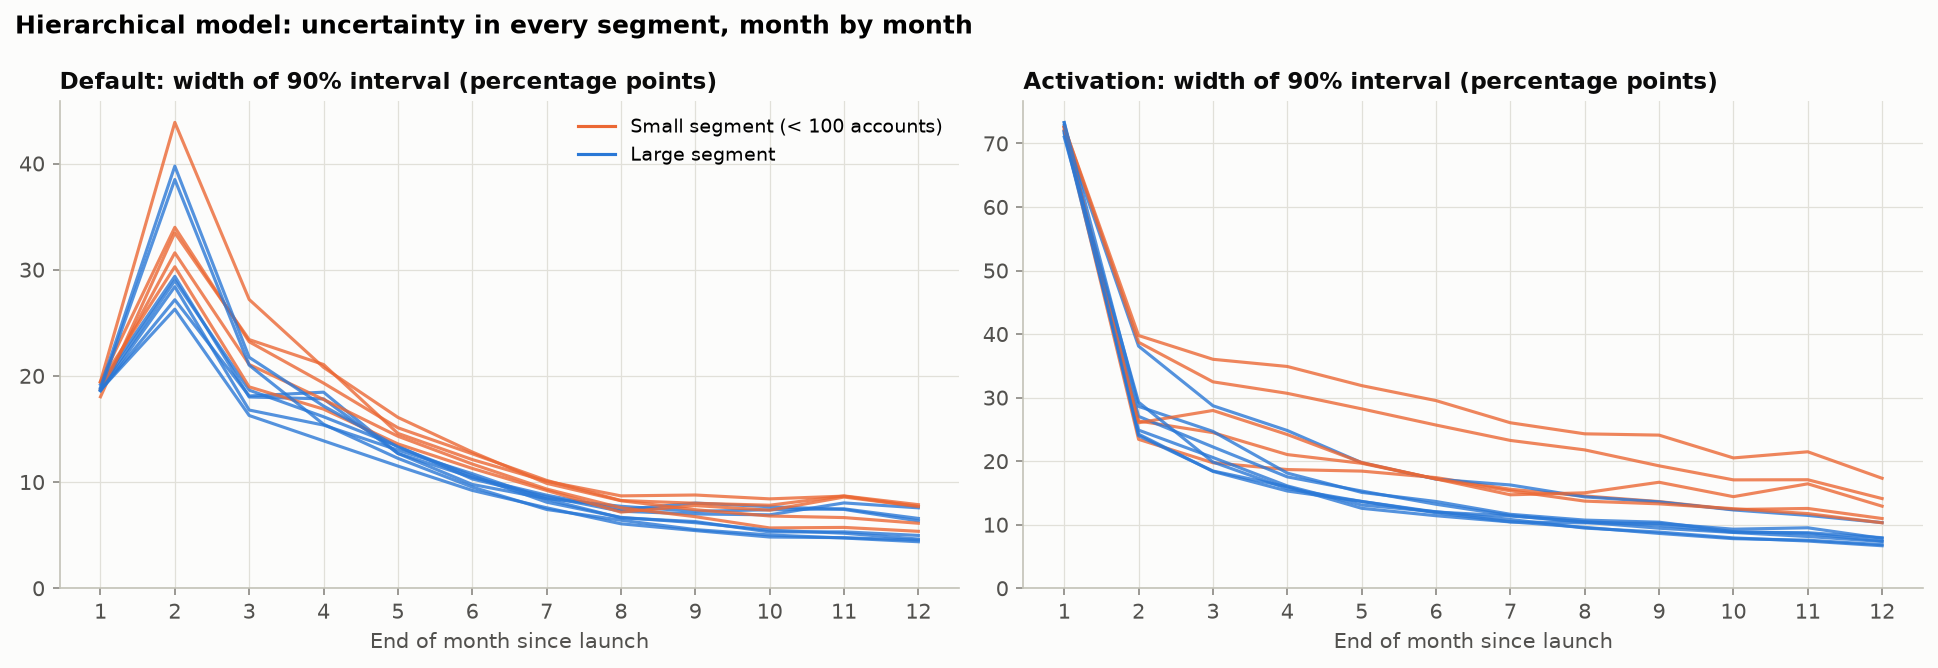

In [11]:
import sequential

sequential.main()
figure("sequential_two_segments.png")
figure("sequential_interval_width.png")

## Stage 6: from posterior to credit limit

Per activated account over one year:

* card spend = E[min(monthly spend need, limit)]
* revenue = card spend x (12 x 1.5% interchange + (24% APR - 5% funding) x 30% revolved)
* loss = PD x 85% LGD x 90% of the limit drawn at default

The suggested limit maximises posterior expected profit, subject to
**P(expected loss > 50% of revenue) < 5%** over the posterior draws. These economic numbers are
assumptions (see `ASSUMPTIONS` in `src/decision.py`), not market data.

In [12]:
import decision

decision.main()

Spend: pooled log-sd 0.62 (true 0.6)
                                 none  oracle  partial  n_accounts  pd_mean  pd_q95  risk_rule_binds  pd_mean_none  pd_q95_none  true_default_rate
segment                                                                                                                                           
Construction | Micro                0    2000     1500         600    0.088   0.124             True         0.110        0.154              0.105
Retail | Micro                   2250    2000     2250         520    0.049   0.073            False         0.045        0.074              0.064
Professional Services | Micro    2250    2000     2000         450    0.048   0.072            False         0.034        0.062              0.049
Professional Services | Small    3500    5250     4500         300    0.051   0.079            False         0.062        0.108              0.035
Construction | Small             4500    5750     5500         260    0.074   0.1

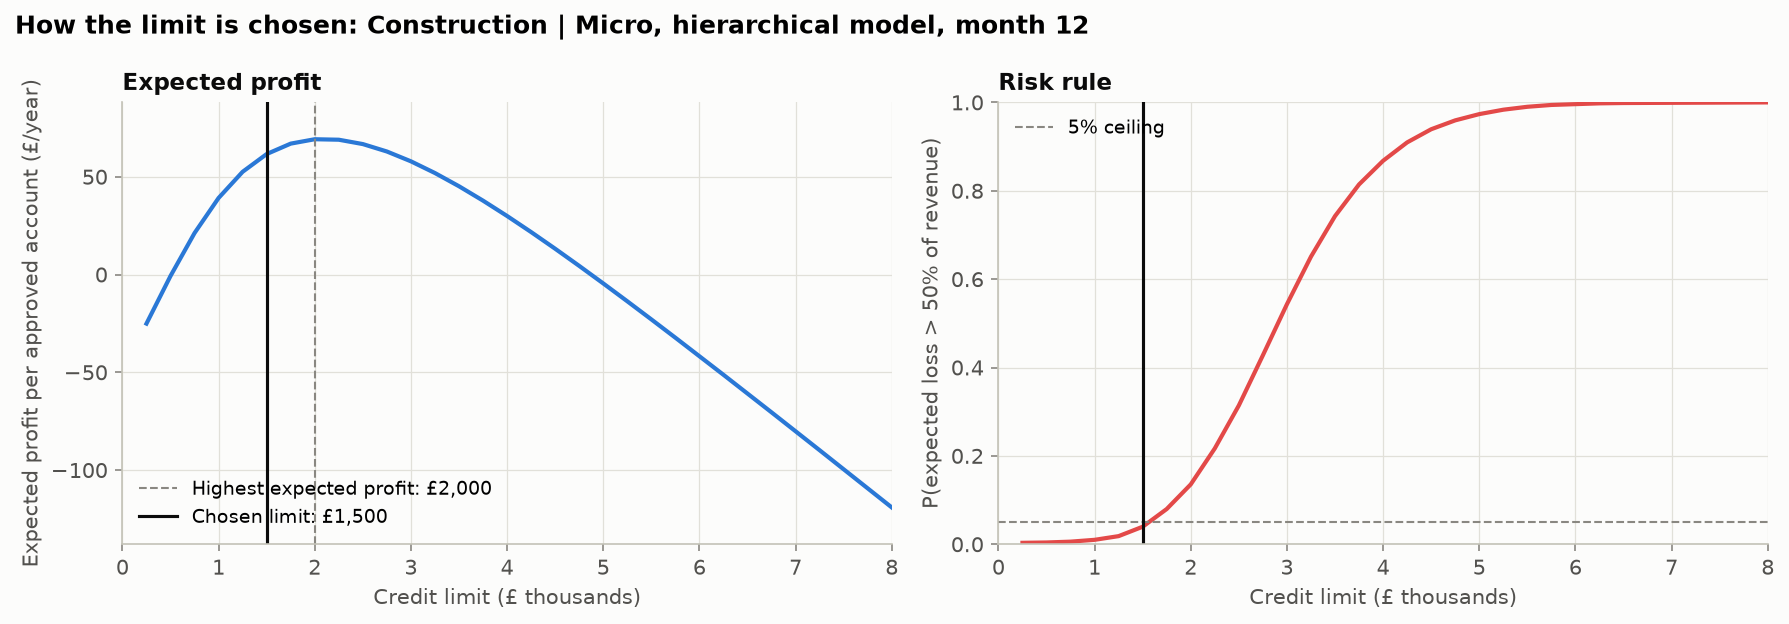

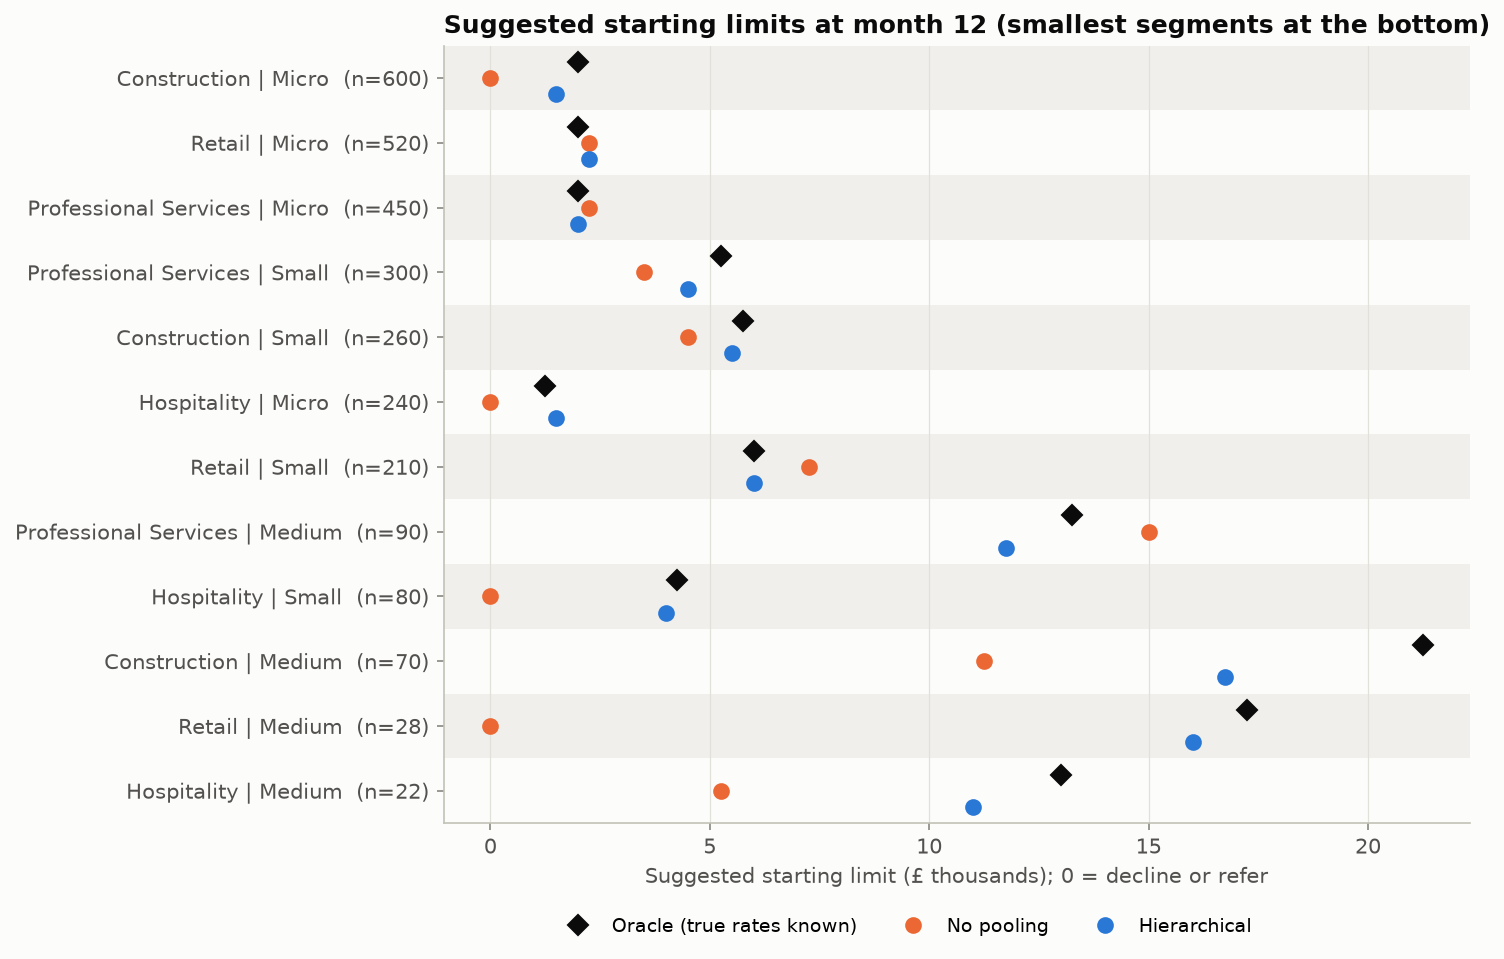

In [13]:
figure("decision_rule_example.png")
figure("decision_limits_by_segment.png", width=800)

Each model's month-12 limits, scored by the profit they would truly earn (using the true rates, which a
real lender would not know). The "oracle" knows the true rates exactly.

In [14]:
final = report("decision_limits_month12.csv")
final.groupby("model")["true_profit_segment"].sum().rename("true yearly profit (GBP)").round(0)

model
none       555585.0
oracle     672981.0
partial    665259.0
Name: true yearly profit (GBP), dtype: float64

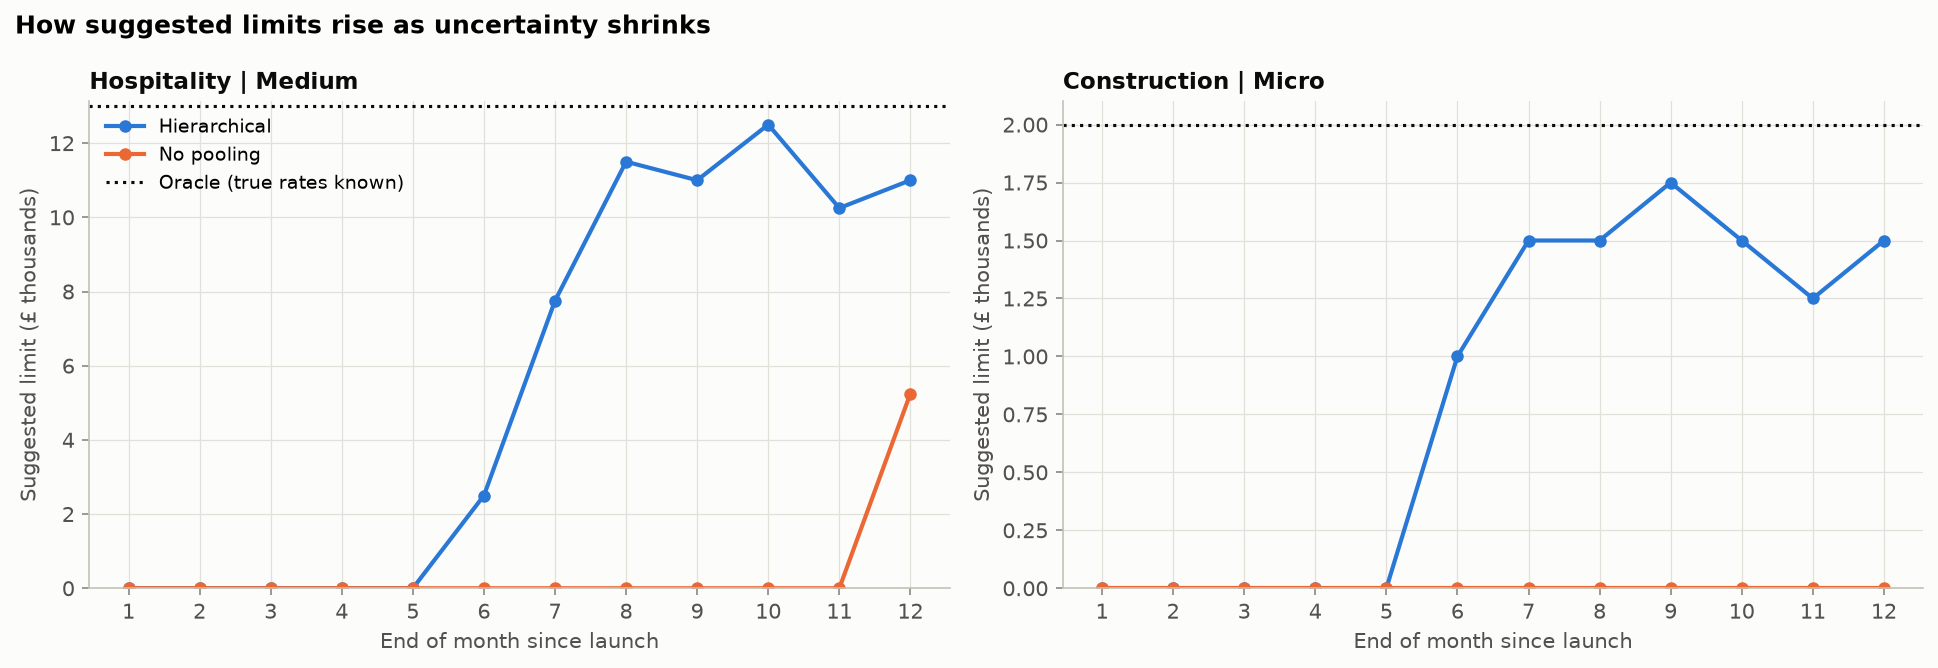

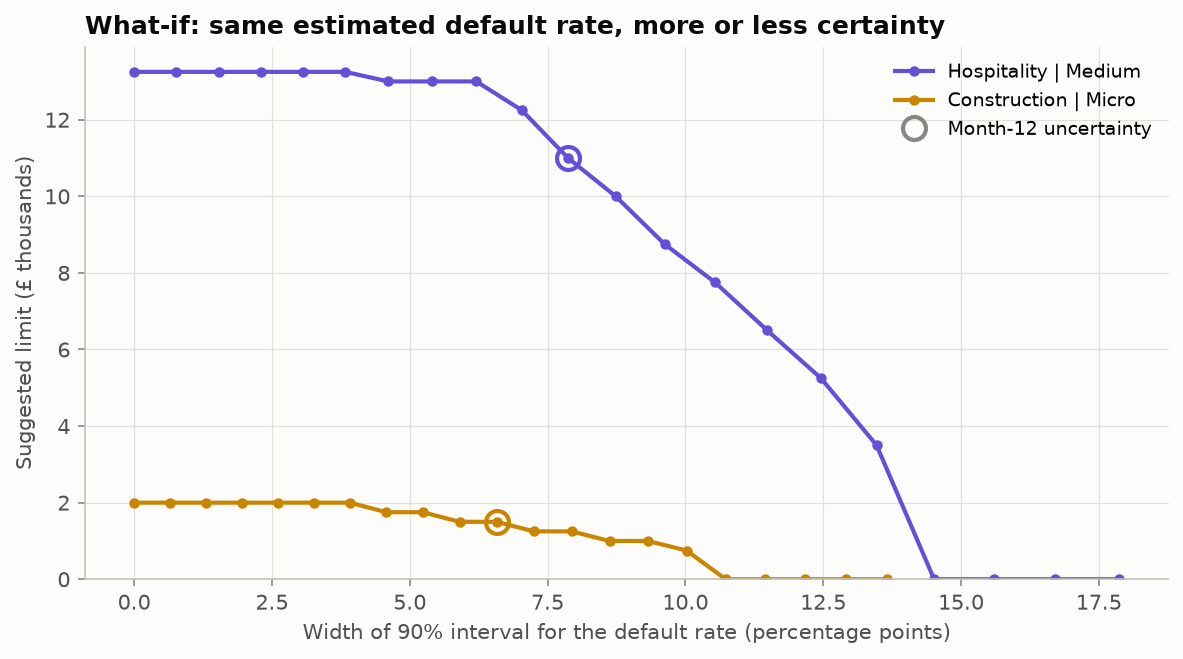

In [15]:
figure("decision_limits_over_time.png")
figure("decision_limit_vs_uncertainty.png", width=750)

## Summary and limitations

* With thin data, no pooling is not "cautious and accurate": its uncertainty is so wide that it declines
  profitable segments outright. Partial pooling gives usable, well-calibrated estimates for small
  segments, and its limits earned close to what perfect knowledge of the true rates would have earned.
* Partial pooling pulls extreme segments towards the middle. The riskiest segment is under-estimated
  and receives a slightly higher limit than it should; using an upper percentile of risk limits the damage.
* Everything is simulated from a model with the same structure as the one fitted, which flatters the
  model. Real data would bring things this project ignores: changing economic conditions, fraud,
  non-uniform default timing, and uncertainty in spend.
* The profit figures depend entirely on the assumed economics. The comparison between models is the
  meaningful part.